In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

if "target" not in df.columns:
    raise ValueError("The dataset must contain a 'target' column.")

if df.isnull().values.any():
    raise ValueError(
        "Missing values found. Handle them before training."
    )

df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns=["target"]).to_numpy(dtype=float)
y_original = df["target"].to_numpy()

if not np.all(np.isin(np.unique(y_original), [0, 1])):
    raise ValueError("Target must contain binary labels 0 and 1.")

y = np.where(y_original == 1, 1.0, -1.0)

In [3]:
rng = np.random.default_rng(42)

train_indices = []
test_indices = []

for class_label in [-1.0, 1.0]:
    class_indices = np.where(y == class_label)[0]
    rng.shuffle(class_indices)

    test_count = max(
        1, int(round(0.20 * len(class_indices)))
    )

    test_indices.extend(class_indices[:test_count])
    train_indices.extend(class_indices[test_count:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

rng.shuffle(train_indices)
rng.shuffle(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Total unique records:", len(df))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Total unique records: 302
Training records: 241
Testing records: 61


In [4]:
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_std[X_std == 0] = 1.0

X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

In [5]:
class ScratchSVM:

    def __init__(
        self,
        C=1.0,
        learning_rate=0.01,
        epochs=3000
    ):
        self.C = C
        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def decision_function(self, X):
        return X @ self.weights + self.bias

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize hyperplane parameters
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):

            scores = self.decision_function(X)

            margins = y * scores

            active = margins < 1.0

            
            grad_weights = (
                self.weights
                - (self.C / n_samples)
                * (X[active].T @ y[active])
            )

            grad_bias = (
                -(self.C / n_samples)
                * np.sum(y[active])
            )

            self.weights -= (
                self.learning_rate * grad_weights
            )

            self.bias -= (
                self.learning_rate * grad_bias
            )

            if epoch % 10 == 0 or epoch == self.epochs - 1:
                current_scores = self.decision_function(X)
                current_margins = y * current_scores

                hinge_loss = np.maximum(
                    0.0, 1.0 - current_margins
                ).mean()

                regularization = (
                    0.5 * np.sum(self.weights ** 2)
                )

                total_loss = (
                    regularization + self.C * hinge_loss
                )

                self.loss_history.append(total_loss)

        return self

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0.0, 1.0, -1.0)

In [6]:
svm = ScratchSVM(
    C=1.0,
    learning_rate=0.01,
    epochs=3000
)

svm.fit(X_train, y_train)

print("\nSVM training completed.")
print("Learned weights:")
print(svm.weights)
print("Learned bias:", svm.bias)


SVM training completed.
Learned weights:
[-0.03321431 -0.12314771  0.23349091 -0.05050162 -0.01010602  0.0282259
  0.08167615  0.19636922 -0.23405744 -0.15303533  0.14328061 -0.19263436
 -0.11138008]
Learned bias: 0.21979253112032837


In [7]:
y_pred = svm.predict(X_test)

TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == -1) & (y_pred == -1))
FP = np.sum((y_test == -1) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == -1))

accuracy = (TP + TN) / len(y_test)

precision = (
    TP / (TP + FP)
    if (TP + FP) > 0 else 0.0
)

recall = (
    TP / (TP + FN)
    if (TP + FN) > 0 else 0.0
)

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0.0
)

print("\n" + "=" * 55)
print("SCRATCH SVM CLASSIFICATION RESULTS")
print("=" * 55)

print(f"True Positives:  {TP}")
print(f"True Negatives:  {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")

print(f"\nAccuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1_score:.4f}")


SCRATCH SVM CLASSIFICATION RESULTS
True Positives:  32
True Negatives:  20
False Positives: 8
False Negatives: 1

Accuracy:  0.8525
Precision: 0.8000
Recall:    0.9697
F1 Score:  0.8767


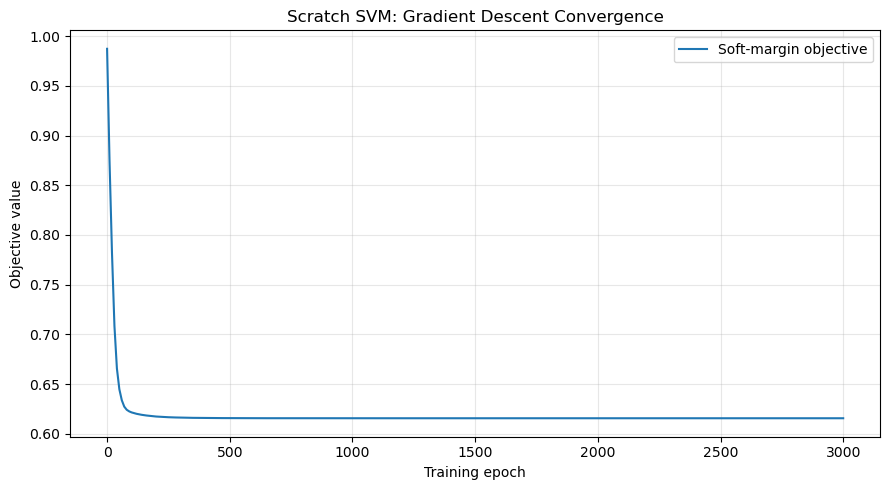

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(len(svm.loss_history)) * 10,
    svm.loss_history,
    label="Soft-margin objective"
)

plt.xlabel("Training epoch")
plt.ylabel("Objective value")
plt.title("Scratch SVM: Gradient Descent Convergence")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

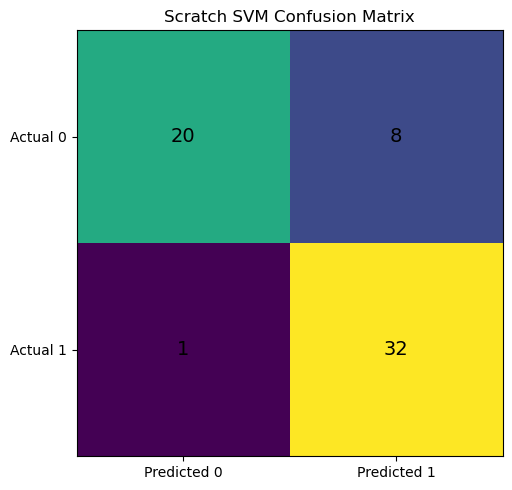

In [9]:
confusion = np.array([
    [TN, FP],
    [FN, TP]
])

fig, ax = plt.subplots(figsize=(6, 5))

ax.imshow(confusion)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(["Predicted 0", "Predicted 1"])
ax.set_yticklabels(["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(confusion[i, j]),
            ha="center", va="center",
            fontsize=14
        )

ax.set_title("Scratch SVM Confusion Matrix")
plt.tight_layout()
plt.show()

In [10]:
results = pd.DataFrame({
    "Actual": np.where(y_test == 1, 1, 0),
    "Predicted": np.where(y_pred == 1, 1, 0),
    "Decision_Score": svm.decision_function(X_test)
})

results.to_csv("scratch_svm_predictions.csv", index=False)

print("\nPredictions saved to scratch_svm_predictions.csv")



Predictions saved to scratch_svm_predictions.csv
